### Accessing Google Sheets from Drive

To access Google Sheets from your Drive in Colab, you'll typically need to:
1.  Install the `gspread` library.
2.  Authenticate your Google account to grant necessary permissions.
3.  Use the sheet's URL to open it and read its data.

In [ ]:
# Install gspread library
!pip install gspread

In [ ]:
import pandas as pd
import seaborn as sns
import gspread
from google.colab import auth
import google.auth

# Authenticate with Google Colab
auth.authenticate_user()

# Get user credentials and authorize gspread to access your Google Sheets
credentials, project_id = google.auth.default()
gc = gspread.authorize(credentials)


# New Section
Load the dataset into the project and display the columns information

In [ ]:
data = pd.read_csv('/content/big_mart_sales.csv')
print(data)

     Item_Identifier  Item_Weight Item_Fat_Content  Item_Visibility  \
0              FDA15        9.300          Low Fat         0.016047   
1              DRC01        5.920          Regular         0.019278   
2              FDN15       17.500          Low Fat         0.016760   
3              FDX07       19.200          Regular         0.000000   
4              NCD19        8.930          Low Fat         0.000000   
...              ...          ...              ...              ...   
8518           FDF22        6.865          Low Fat         0.056783   
8519           FDS36        8.380          Regular         0.046982   
8520           NCJ29       10.600          Low Fat         0.035186   
8521           FDN46        7.210          Regular         0.145221   
8522           DRG01       14.800          Low Fat         0.044878   

                  Item_Type  Item_MRP Outlet_Identifier  \
0                     Dairy  249.8092            OUT049   
1               Soft Drinks  

Check which columns have missing values

In [ ]:
data.isna().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


Get the shape of the data

In [ ]:

print(data.shape)


(8523, 12)


Display the data types of all the columns

In [ ]:

print(data.dtypes)

Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
dtype: object


Get the info regarding all the tables

In [ ]:

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
None


# **Data** **Visualization**

import matplotlib

In [ ]:
import matplotlib.pyplot as plt

Use matplotlib to display a graph that shows the relationship between the item_type and item_outlet_sales

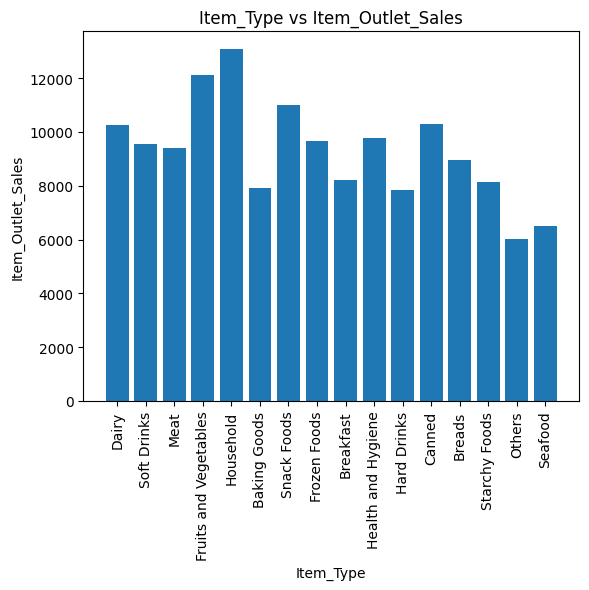

In [ ]:
x=data['Item_Type']
y=data['Item_Outlet_Sales']
plt.bar(x,y)
plt.xlabel('Item_Type')
plt.ylabel('Item_Outlet_Sales')
plt.title('Item_Type vs Item_Outlet_Sales')
plt.xticks(rotation=90)
plt.show()

Determine if fat content affects sales

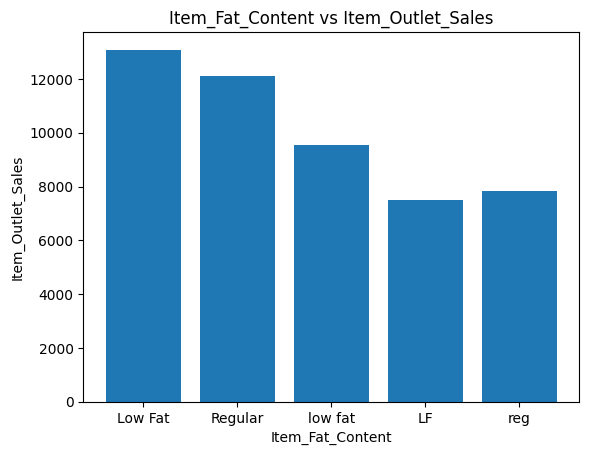

In [ ]:
import pandas as pd

data = pd.read_csv('/content/big_mart_sales.csv')
x = data['Item_Fat_Content']
y = data['Item_Outlet_Sales']
plt.bar(x,y)
plt.xlabel('Item_Fat_Content')
plt.ylabel('Item_Outlet_Sales')
plt.title('Item_Fat_Content vs Item_Outlet_Sales')
#plt.xticks(rotation=90)
plt.show()

Display a graph about outlet_sales and the frequency

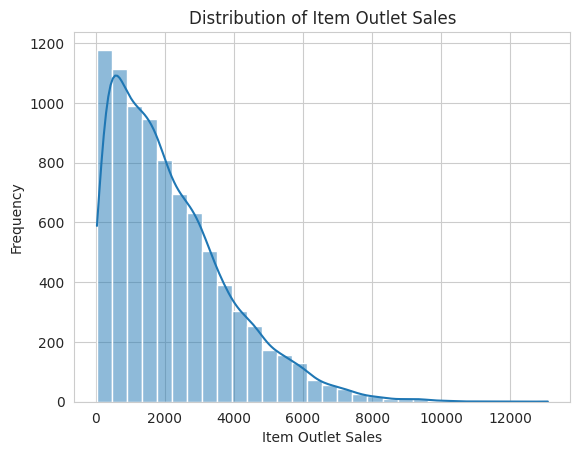

In [ ]:
sns.histplot(data['Item_Outlet_Sales'], bins=30, kde=True)
plt.title('Distribution of Item Outlet Sales')
plt.xlabel('Item Outlet Sales')
plt.ylabel('Frequency')
plt.show()

Determine the relationship between outlet_sales and outlet_type

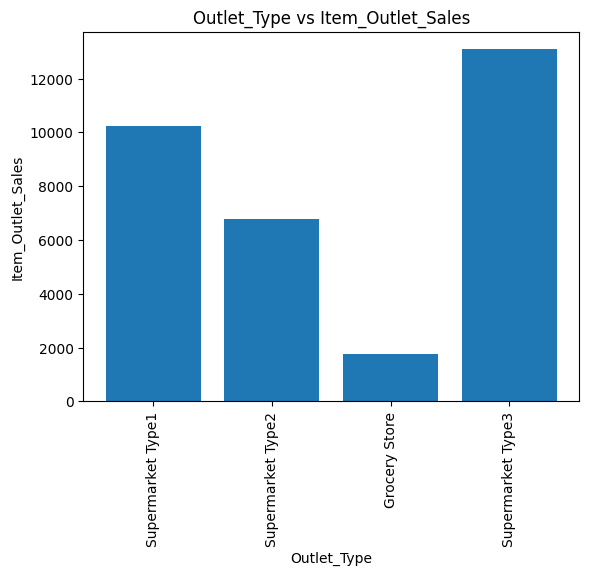

In [ ]:
x= data['Outlet_Type']
y= data['Item_Outlet_Sales']
plt.bar(x,y)
plt.xlabel('Outlet_Type')
plt.ylabel('Item_Outlet_Sales')
plt.title('Outlet_Type vs Item_Outlet_Sales')
plt.xticks(rotation=90)
plt.show()

Determine if item_visibility affects its sales

<function matplotlib.pyplot.show(close=None, block=None)>

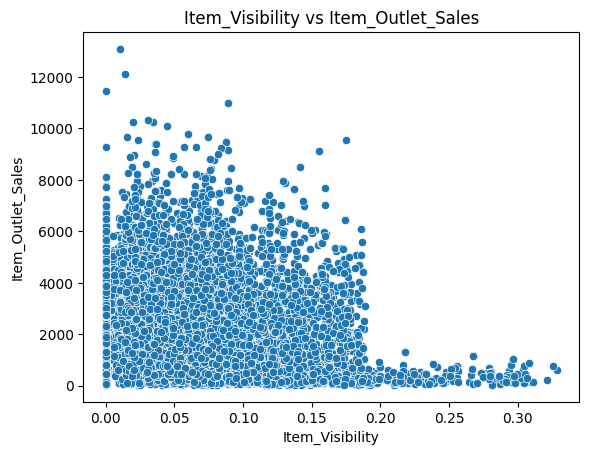

In [ ]:


sns.scatterplot(data=data, x='Item_Visibility', y='Item_Outlet_Sales')
plt.xlabel('Item_Visibility')
plt.ylabel('Item_Outlet_Sales')
plt.title('Item_Visibility vs Item_Outlet_Sales')
plt.show

Which item types have the highest sales value

<function matplotlib.pyplot.show(close=None, block=None)>

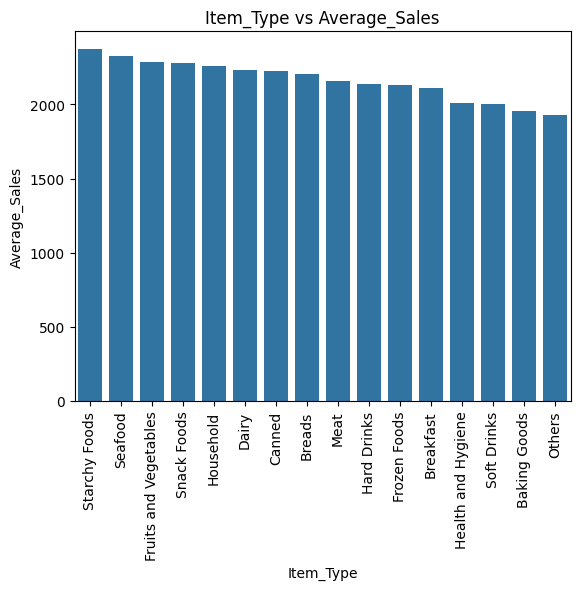

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the dataset

#Group the data firstly according to the item_type, then calculate the mean usung the item_outlet_sales
data = pd.read_csv('/content/big_mart_sales.csv')
avg_sales = data.groupby('Item_Type')['Item_Outlet_Sales'].mean()
avg_sales.sort_values(ascending=False, inplace=True)
sns.barplot(x=avg_sales.index, y=avg_sales)
plt.xlabel('Item_Type')
plt.ylabel('Average_Sales')
plt.title('Item_Type vs Average_Sales')
plt.xticks(rotation=90)
plt.show

Determine if outlet type has an impact on the sales eg what do most people buy at a grocery store outlet.

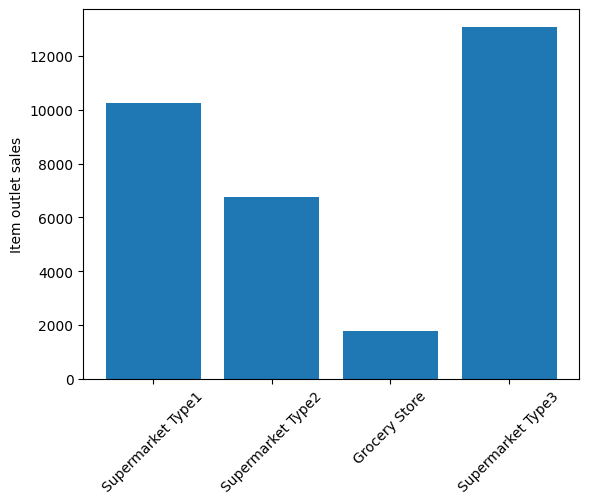

In [ ]:
x= data['Outlet_Type']
y = data['Item_Outlet_Sales']
plt.bar(x,y)
plt.xticks(rotation = 45)
plt.ylabel('Outlet type')
plt.ylabel('Item outlet sales')
plt.show()


Do older outlets have different different sales compared to newer ones

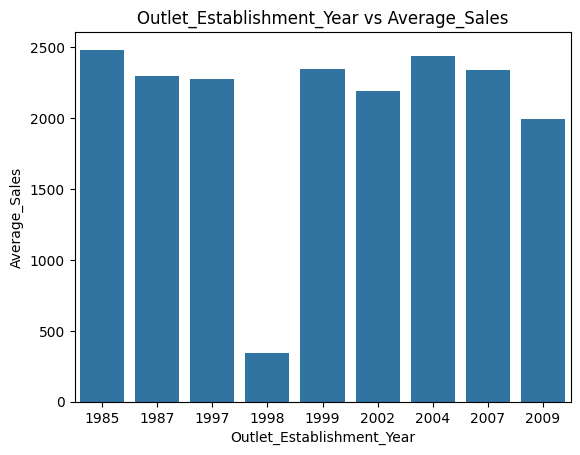

In [ ]:
year_sales = data.groupby('Outlet_Establishment_Year')['Item_Outlet_Sales'].mean()
sns.barplot(x=year_sales.index, y=year_sales)
plt.xlabel('Outlet_Establishment_Year')
plt.ylabel('Average_Sales')
plt.title('Outlet_Establishment_Year vs Average_Sales')
plt.show()

Create a correlation to better understand the relatioship between the columns.


In [ ]:
correlation = data.corr(numeric_only=True)
print(correlation)

                           Item_Weight  Item_Visibility  Item_MRP  \
Item_Weight                   1.000000        -0.014048  0.027141   
Item_Visibility              -0.014048         1.000000 -0.001315   
Item_MRP                      0.027141        -0.001315  1.000000   
Outlet_Establishment_Year    -0.011588        -0.074834  0.005020   
Item_Outlet_Sales             0.014123        -0.128625  0.567574   

                           Outlet_Establishment_Year  Item_Outlet_Sales  
Item_Weight                                -0.011588           0.014123  
Item_Visibility                            -0.074834          -0.128625  
Item_MRP                                    0.005020           0.567574  
Outlet_Establishment_Year                   1.000000          -0.049135  
Item_Outlet_Sales                          -0.049135           1.000000  


Create a heatMap that displays the correlation created

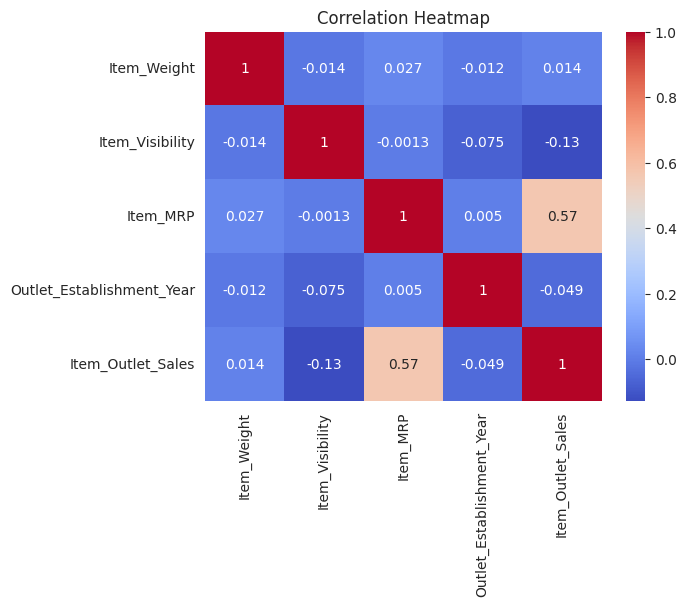

In [ ]:
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Create and display a boxplot for Item_outlet_sales

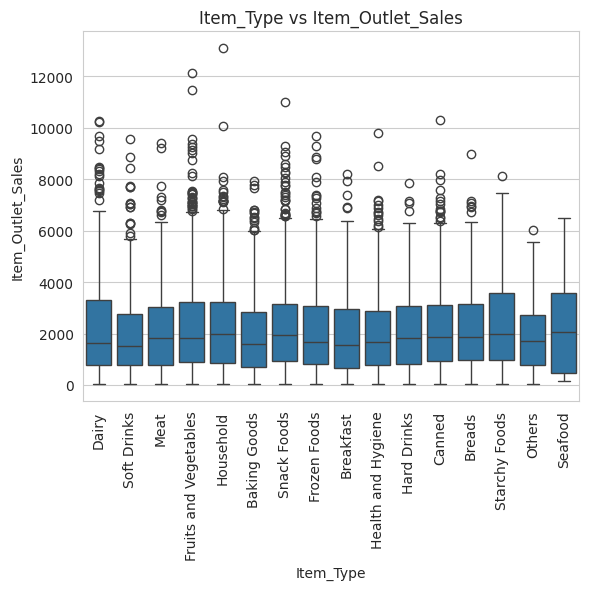

In [ ]:
sns.boxplot(data=data, x='Item_Type', y='Item_Outlet_Sales')
plt.xlabel('Item_Type')
plt.ylabel('Item_Outlet_Sales')
plt.title('Item_Type vs Item_Outlet_Sales')
plt.xticks(rotation=90)
plt.show()

Find the missing values

In [ ]:
data.isna().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


Create a cros tabulation between Outlet_Type and Outlet_size th further investigate the pattern of the missing values

In [ ]:
pd.crosstab(data['Outlet_Type'], data['Outlet_Size'])

Outlet_Size,High,Medium,Small
Outlet_Type,,,
Grocery Store,0,0,528
Supermarket Type1,932,930,1860
Supermarket Type2,0,928,0
Supermarket Type3,0,935,0


In [ ]:
pd.crosstab(data['Outlet_Type'], data['Outlet_Size'])

Outlet_Size,High,Medium,Small
Outlet_Type,,,
Grocery Store,0,0,528
Supermarket Type1,932,930,1860
Supermarket Type2,0,928,0
Supermarket Type3,0,935,0


### Handling Missing Values

From the `data.isna().sum()` output, we can see missing values in 'Item_Weight' and 'Outlet_Size'. We'll impute 'Item_Weight' with the mean and 'Outlet_Size' with the mode, as it's a categorical feature.

### Descriptive Statistics

Let's look at the basic descriptive statistics for the numerical columns to get an overview of the data distribution.

In [ ]:
# Display descriptive statistics for numerical columns
display(data.describe())

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


### Data Visualization

Now, let's create some visualizations to understand the distributions and relationships within the data.

First, a histogram of 'Item_Outlet_Sales' to see its distribution.

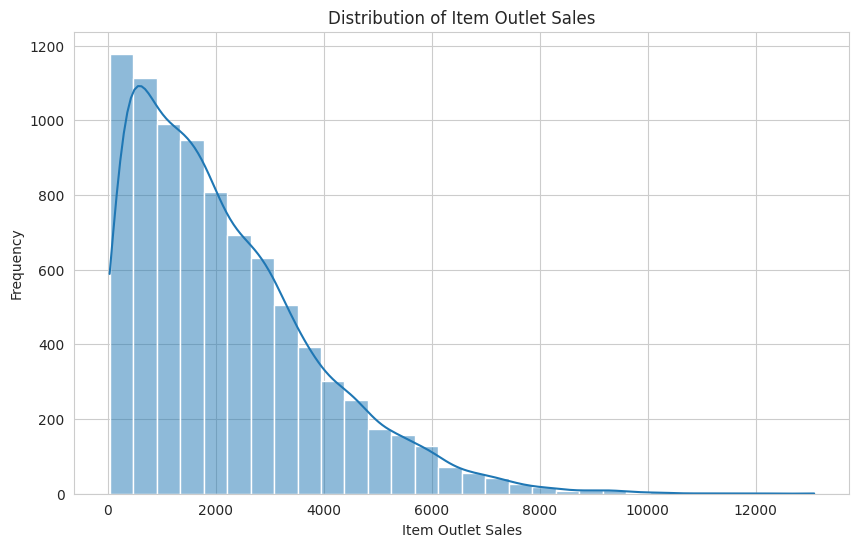

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for seaborn plots
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(data['Item_Outlet_Sales'], bins=30, kde=True)
plt.title('Distribution of Item Outlet Sales')
plt.xlabel('Item Outlet Sales')
plt.ylabel('Frequency')
plt.show()

Next, let's visualize the distribution of sales across different 'Outlet_Type' categories using a box plot.

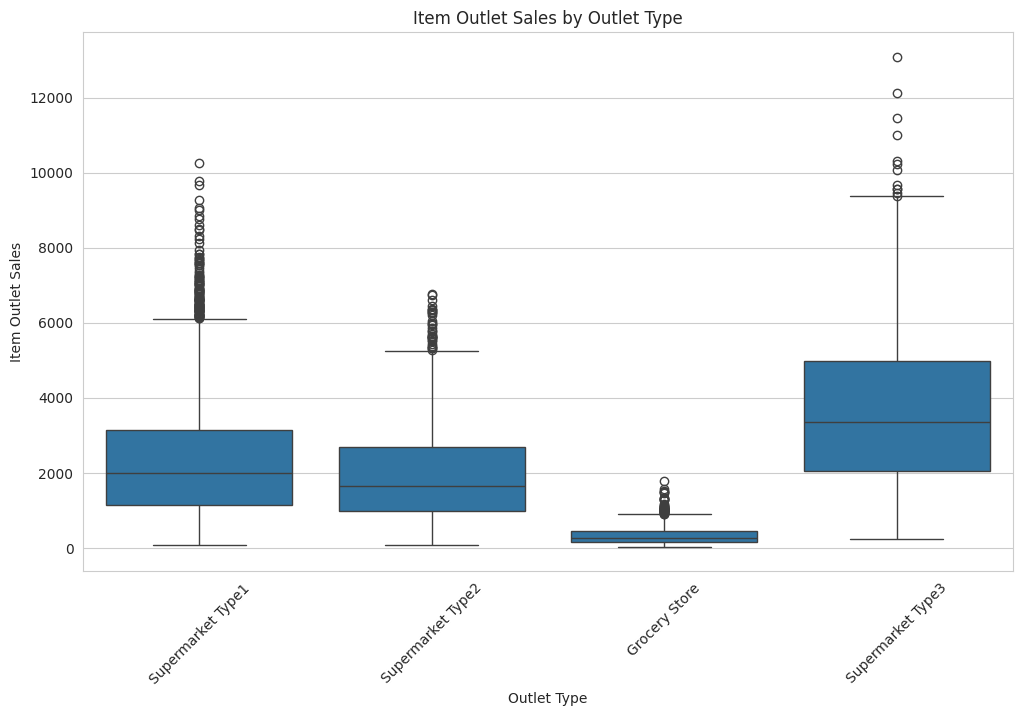

In [ ]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Outlet_Type', y='Item_Outlet_Sales', data=data)
plt.title('Item Outlet Sales by Outlet Type')
plt.xlabel('Outlet Type')
plt.ylabel('Item Outlet Sales')
plt.xticks(rotation=45)
plt.show()

Let's also look at the impact of 'Item_Fat_Content' on 'Item_Outlet_Sales'.

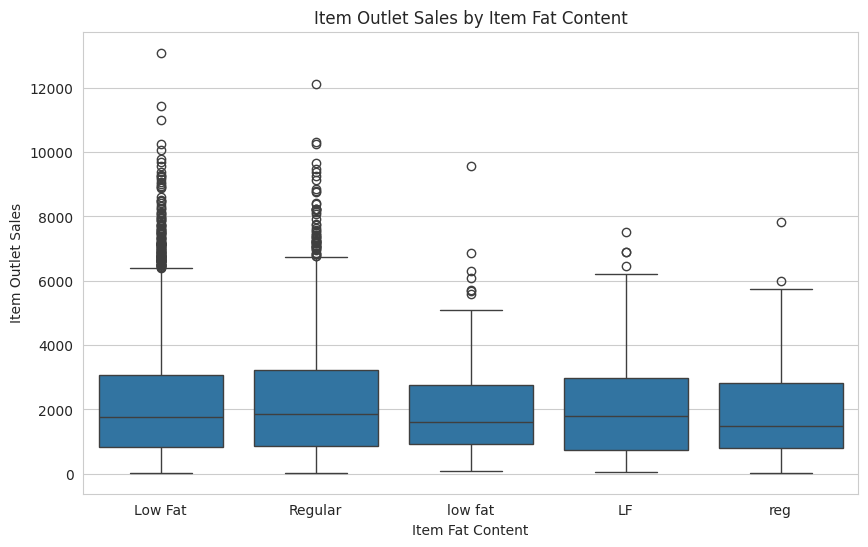

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Item_Fat_Content', y='Item_Outlet_Sales', data=data)
plt.title('Item Outlet Sales by Item Fat Content')
plt.xlabel('Item Fat Content')
plt.ylabel('Item Outlet Sales')
plt.show()

### Cleaning 'Item_Fat_Content'

We noticed inconsistent spellings in 'Item_Fat_Content' ('Low Fat', 'low fat', 'LF', 'Regular', 'reg'). Let's standardize these to 'Low Fat' and 'Regular' for better analysis.

In [ ]:
# Standardize 'Item_Fat_Content' values
data['Item_Fat_Content'] = data['Item_Fat_Content'].replace({
    'low fat': 'Low Fat',
    'LF': 'Low Fat',
    'reg': 'Regular'
})

print("Unique values in 'Item_Fat_Content' after cleaning:")
display(data['Item_Fat_Content'].value_counts())

Unique values in 'Item_Fat_Content' after cleaning:


,count
Item_Fat_Content,
Low Fat,5517
Regular,3006


### Analyzing Sales by Outlet Location Type

Let's visualize the relationship between 'Outlet_Location_Type' and 'Item_Outlet_Sales' to see if geographical location impacts sales.

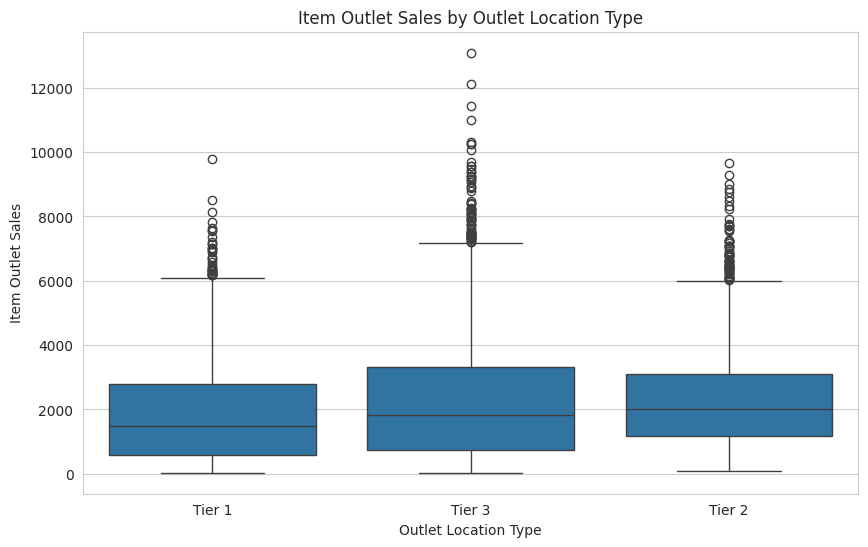

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Outlet_Location_Type', y='Item_Outlet_Sales', data=data)
plt.title('Item Outlet Sales by Outlet Location Type')
plt.xlabel('Outlet Location Type')
plt.ylabel('Item Outlet Sales')
plt.show()

### Exploring Item Type vs. Sales

Finally, let's look at the distribution of 'Item_Outlet_Sales' across different 'Item_Type' categories. Since there are many item types, we might want to aggregate or focus on the top ones.

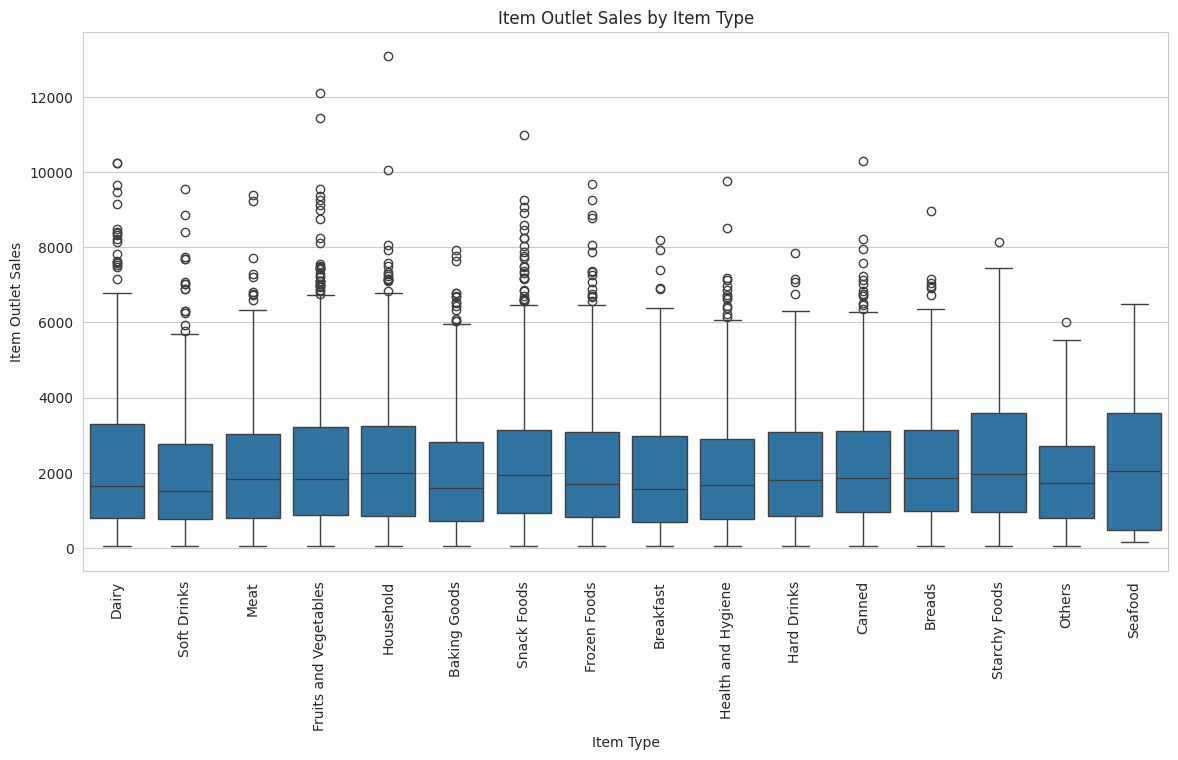

In [ ]:
plt.figure(figsize=(14, 7))
sns.boxplot(x='Item_Type', y='Item_Outlet_Sales', data=data)
plt.title('Item Outlet Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Item Outlet Sales')
plt.xticks(rotation=90)
plt.show()

### Correlation Analysis

Let's analyze the correlation between numerical features to identify strong relationships that might be useful for modeling or further insights.

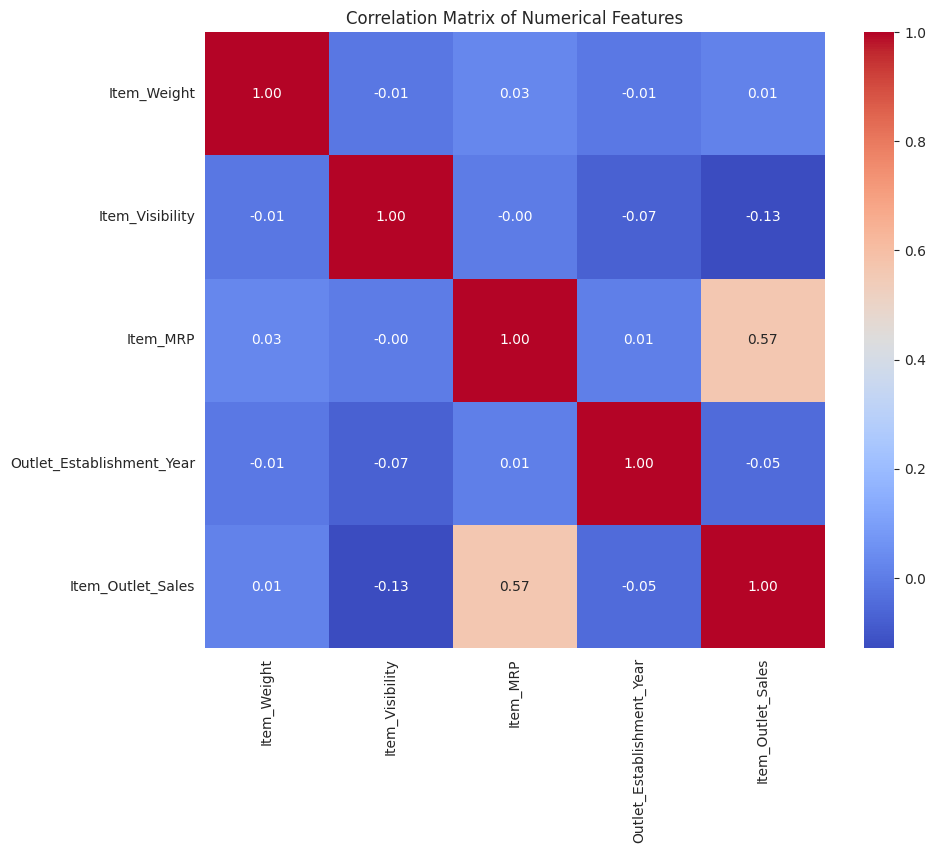

In [ ]:
# Select only numerical columns for correlation calculation
numerical_data = data.select_dtypes(include=['number'])

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### Correlation Analysis

Let's analyze the correlation between numerical features to identify strong relationships that might be useful for modeling or further insights.

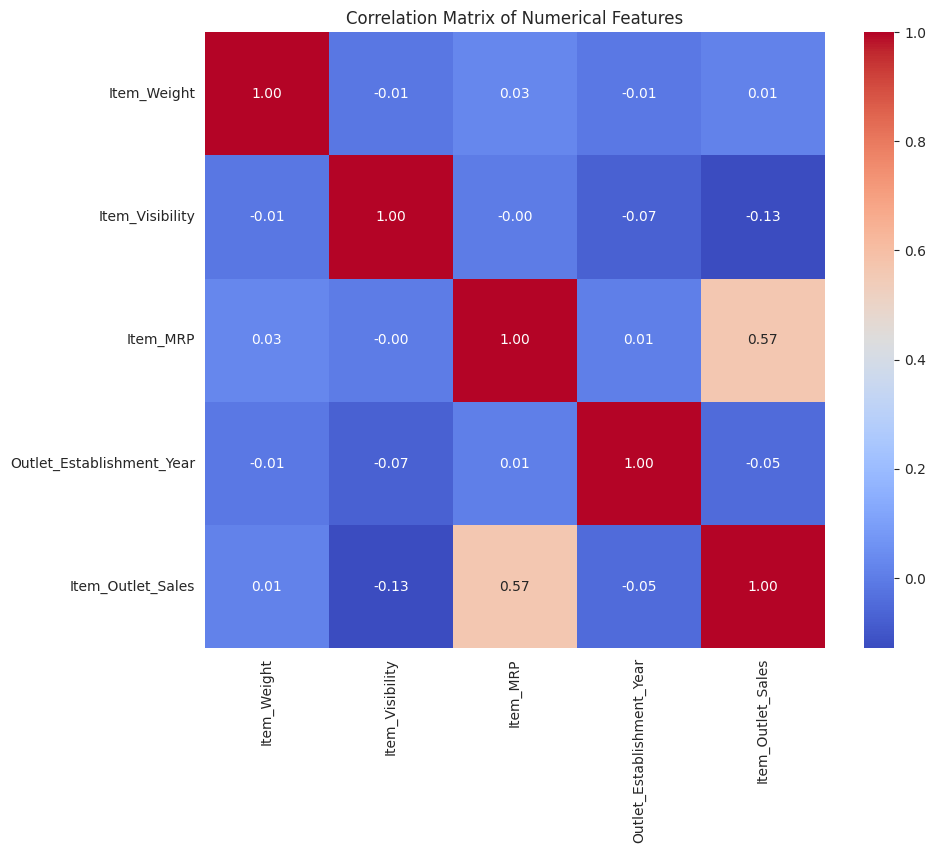

In [ ]:
# Select only numerical columns for correlation calculation
numerical_data = data.select_dtypes(include=['number'])

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()